# 05a - Model Comparison (LogReg, Random Forest, CatBoost)

Here we compare the three models trained on results/train.csv using the same 5-fold CV splits. results/test.csv is not used here.


In [1]:
# load shared helpers, train data, and saved experiment outputs
import json
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

from src import evaluate, preprocess

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 25)

df, _ = preprocess.load_train_data()
y = df["target"].to_numpy()
splits = evaluate.make_cv_splits(df)

exp_dir = Path("../experiments")
model_specs = [
    ("logreg", "LogReg"),
    ("rf", "Random Forest"),
    ("catboost", "CatBoost"),
]

cv_data = {}
oof_probs = {}
for key, label in model_specs:
    cv_data[key] = json.loads((exp_dir / f"{key}_cv.json").read_text(encoding="utf-8"))
    oof_df = pd.read_csv(exp_dir / f"{key}_oof.csv")
    assert list(oof_df.columns) == ["cycle", "seqn", "target", "oof_prob"], key
    assert len(oof_df) == len(df), key
    assert (oof_df[["cycle", "seqn", "target"]].to_numpy() == df[["cycle", "seqn", "target"]].to_numpy()).all(), key
    assert oof_df["oof_prob"].notna().all(), key
    oof_probs[key] = oof_df["oof_prob"].to_numpy()

print("Loaded and verified all 3 models:", {k: cv_data[k]["best_feature_set"] for k, _ in model_specs})


Loaded and verified all 3 models: {'logreg': 'practical_20', 'rf': 'practical_20', 'catboost': 'practical_20'}


## 1. Feature Set Comparison Across All 3 Models

First we compare how LogReg, Random Forest, and CatBoost perform across all 6 shared feature sets (from ada_like_7 to all_64) before hyperparameter tuning.


model,LogReg,Random Forest,CatBoost
feature_set,,,
ada_like_7,0.7408,0.7381,0.7344
custom_10,0.7571,0.7486,0.7543
no_device_15,0.7621,0.7577,0.7595
practical_20,0.7624,0.7603,0.7613
top_30,0.7612,0.7599,0.7623
all_64,0.7611,0.7564,0.7611


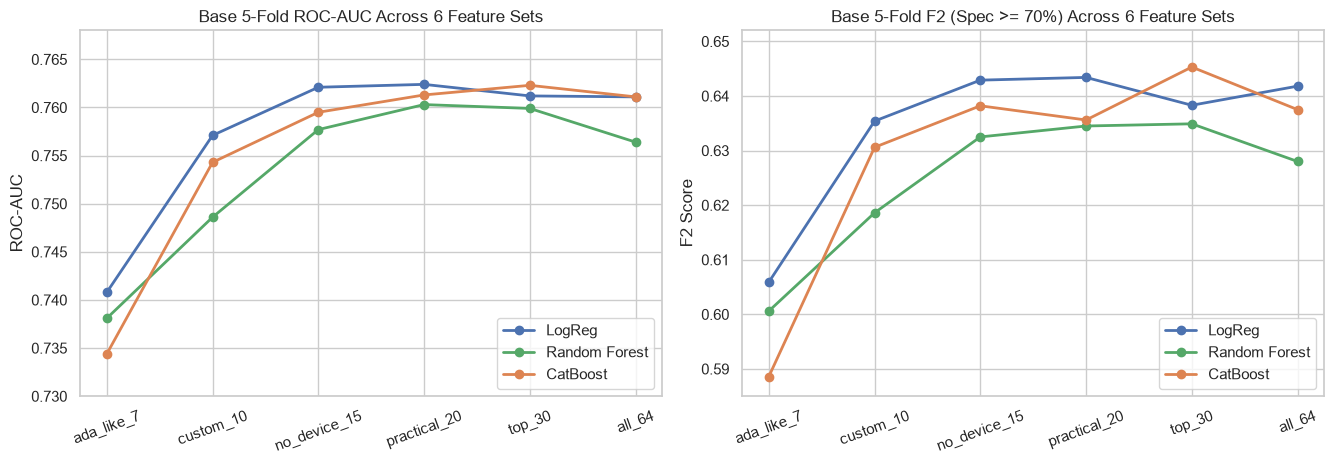

In [2]:
# combine base feature set tables from all 3 cv json files
set_order = ["ada_like_7", "custom_10", "no_device_15", "practical_20", "top_30", "all_64"]
fs_rows = []
for key, label in model_specs:
    for r in cv_data[key]["feature_set_comparison"]:
        fs_rows.append({
            "model": label,
            "feature_set": r["feature_set"],
            "n_features": r["n_features"],
            "roc_auc": r["roc_auc"],
            "pr_auc": r["pr_auc"],
            "f2": r["f2"],
            "brier": r["brier"],
        })

fs_all = pd.DataFrame(fs_rows)
fs_pivot_auc = fs_all.pivot(index="feature_set", columns="model", values="roc_auc").reindex(set_order)[["LogReg", "Random Forest", "CatBoost"]]
fs_pivot_f2 = fs_all.pivot(index="feature_set", columns="model", values="f2").reindex(set_order)[["LogReg", "Random Forest", "CatBoost"]]
display(fs_pivot_auc)

# plot ROC-AUC and F2 trends across the 6 feature sets
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
palette = {"LogReg": "#4c72b0", "Random Forest": "#55a868", "CatBoost": "#dd8452"}

for label in ["LogReg", "Random Forest", "CatBoost"]:
    sub = fs_all[fs_all["model"] == label].set_index("feature_set").reindex(set_order)
    axes[0].plot(set_order, sub["roc_auc"], marker="o", linewidth=2, label=label, color=palette[label])
    axes[1].plot(set_order, sub["f2"], marker="o", linewidth=2, label=label, color=palette[label])

axes[0].set_title("Base 5-Fold ROC-AUC Across 6 Feature Sets")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_ylim(0.730, 0.768)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(loc="lower right")

axes[1].set_title("Base 5-Fold F2 (Spec >= 70%) Across 6 Feature Sets")
axes[1].set_ylabel("F2 Score")
axes[1].set_ylim(0.585, 0.652)
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


All three models improve clearly as we add core survey and body features, and reach their best region around 20-30 features. Using all 64 columns adds noise rather than useful signal.


## 2. Tuned Models Side by Side (practical_20)

All three teams selected practical_20 (20 survey and basic body measures) for the final model. Below we compare their tuned 5-fold out-of-fold metrics, ROC/PR curves, calibration curves, and fixed referral budgets (20%, 30%, 40%).


,model,feature_set,roc_auc,auc_std,pr_auc,pr_std,f2,recall,specificity,precision,brier,threshold,tp,fp,tn,fn
0,LogReg,practical_20,0.7626,0.0105,0.5448,0.0124,0.6439,0.6966,0.7003,0.4944,0.1723,0.313,2553,2611,6102,1112
1,Random Forest,practical_20,0.7610,0.0099,0.5414,0.0176,0.6372,0.6876,0.7024,0.4929,0.1726,0.343,2520,2593,6120,1145
2,CatBoost,practical_20,0.7641,0.0098,0.5440,0.0145,0.6438,0.6963,0.7008,0.4947,0.1718,0.326,2552,2607,6106,1113


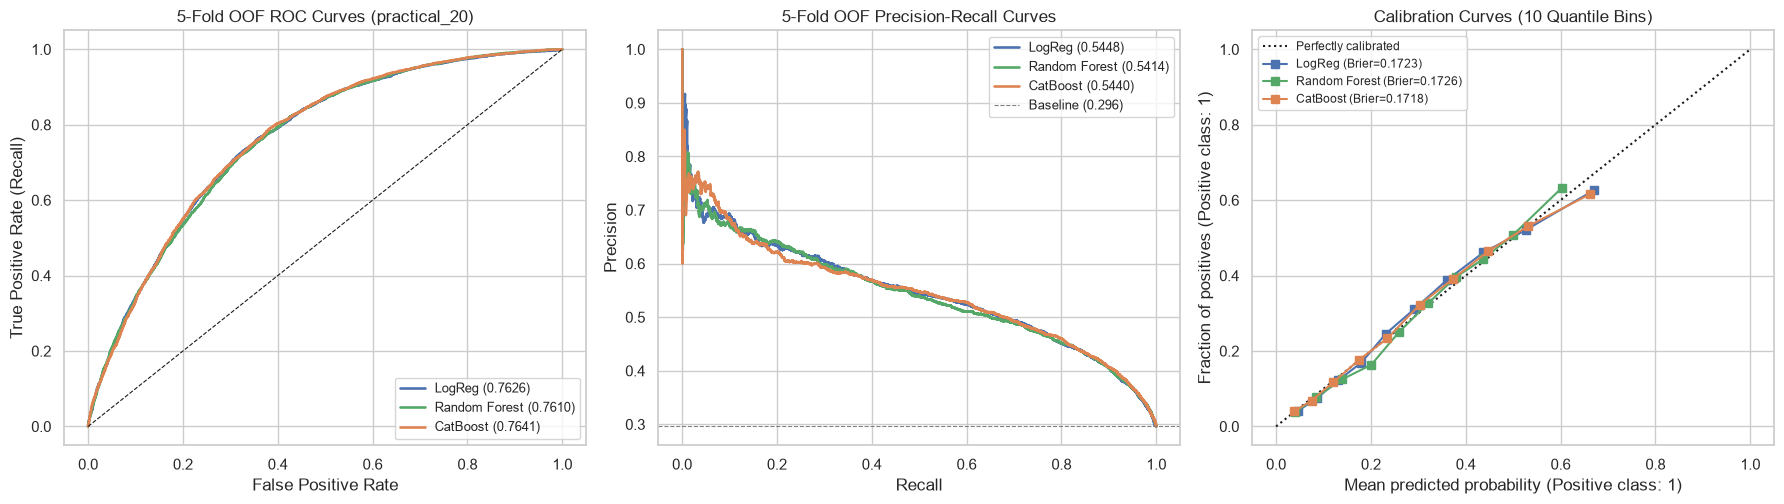

In [3]:
# build side-by-side summary table of the 3 tuned models with fold std
summary_rows = []
for key, label in model_specs:
    probs = oof_probs[key]
    m = cv_data[key]["best_metrics"]
    fold_aucs = [roc_auc_score(y[va], probs[va]) for _, va in splits]
    fold_prs = [average_precision_score(y[va], probs[va]) for _, va in splits]
    summary_rows.append({
        "model": label,
        "feature_set": cv_data[key]["best_feature_set"],
        "roc_auc": m["roc_auc"],
        "auc_std": round(float(np.std(fold_aucs)), 4),
        "pr_auc": m["pr_auc"],
        "pr_std": round(float(np.std(fold_prs)), 4),
        "f2": m["f2"],
        "recall": m["recall"],
        "specificity": m["specificity"],
        "precision": m["precision"],
        "brier": m["brier"],
        "threshold": m["threshold"],
        "tp": m["tp"],
        "fp": m["fp"],
        "tn": m["tn"],
        "fn": m["fn"],
    })

comp_df = pd.DataFrame(summary_rows)
display(comp_df)

# plot overlaid ROC, PR, and quantile calibration curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

for key, label in model_specs:
    probs = oof_probs[key]
    m = cv_data[key]["best_metrics"]
    fpr, tpr, _ = roc_curve(y, probs)
    prec, rec, _ = precision_recall_curve(y, probs)
    axes[0].plot(fpr, tpr, linewidth=1.9, label=f"{label} ({m['roc_auc']:.4f})", color=palette[label])
    axes[1].plot(rec, prec, linewidth=1.9, label=f"{label} ({m['pr_auc']:.4f})", color=palette[label])
    CalibrationDisplay.from_predictions(
        y, probs, n_bins=10, strategy="quantile",
        name=f"{label} (Brier={m['brier']:.4f})",
        ax=axes[2], color=palette[label],
    )

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("5-Fold OOF ROC Curves (practical_20)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right", fontsize=9)

axes[1].axhline(y.mean(), color="grey", linestyle="--", linewidth=0.8, label=f"Baseline ({y.mean():.3f})")
axes[1].set_title("5-Fold OOF Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=9)

axes[2].set_title("Calibration Curves (10 Quantile Bins)")
axes[2].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()


,model,referral_rate,n_referred,threshold,recall,precision,specificity,f2,tp
0,LogReg,0.2,2476,0.4784,0.3874,0.5735,0.8788,0.4143,1420
1,LogReg,0.3,3714,0.3982,0.5432,0.5361,0.8022,0.5418,1991
2,LogReg,0.4,4951,0.3241,0.6742,0.4991,0.7154,0.6300,2471
3,Random Forest,0.2,2476,0.4652,0.3855,0.5707,0.8780,0.4123,1413
4,Random Forest,0.3,3713,0.4088,0.5353,0.5284,0.7990,0.5339,1962
5,Random Forest,0.4,4951,0.3517,0.6693,0.4955,0.7133,0.6254,2453
6,CatBoost,0.2,2476,0.4865,0.3872,0.5731,0.8787,0.4140,1419
7,CatBoost,0.3,3713,0.4084,0.5441,0.5370,0.8027,0.5426,1994
8,CatBoost,0.4,4951,0.3383,0.6761,0.5005,0.7162,0.6318,2478


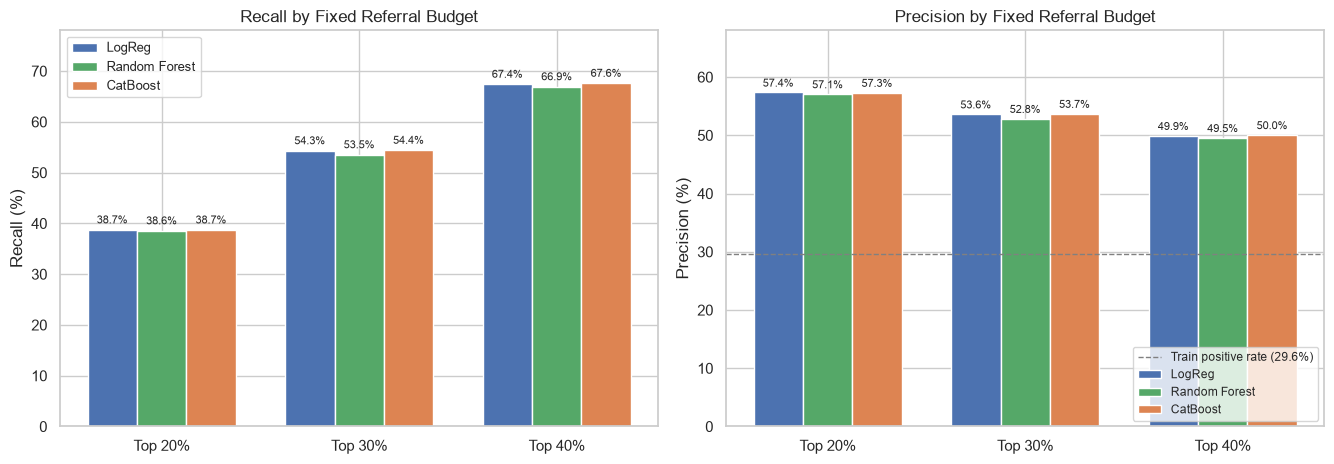

In [4]:
# compare fixed referral rates (top 20%, 30%, 40%) across all 3 models
ref_rows = []
for key, label in model_specs:
    for r in cv_data[key]["referral_table"]:
        ref_rows.append({
            "model": label,
            "referral_rate": r["referral_rate"],
            "n_referred": r.get("referred_count", r.get("n_referred")),
            "threshold": r.get("threshold", r.get("cutoff_prob")),
            "recall": r["recall"],
            "precision": r["precision"],
            "specificity": r["specificity"],
            "f2": r["f2"],
            "tp": r["tp"],
        })

ref_all = pd.DataFrame(ref_rows)
display(ref_all)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
rates = [0.2, 0.3, 0.4]
x = np.arange(len(rates))
w = 0.25

for i, label in enumerate(["LogReg", "Random Forest", "CatBoost"]):
    sub = ref_all[ref_all["model"] == label].set_index("referral_rate").reindex(rates)
    offset = (i - 1) * w
    b1 = axes[0].bar(x + offset, sub["recall"] * 100, width=w, label=label, color=palette[label])
    b2 = axes[1].bar(x + offset, sub["precision"] * 100, width=w, label=label, color=palette[label])
    for b in b1:
        val = b.get_height()
        axes[0].text(b.get_x() + b.get_width() / 2, val + 0.8, f"{val:.1f}%", ha="center", va="bottom", fontsize=8)
    for b in b2:
        val = b.get_height()
        axes[1].text(b.get_x() + b.get_width() / 2, val + 0.6, f"{val:.1f}%", ha="center", va="bottom", fontsize=8)

axes[0].set_xticks(x)
axes[0].set_xticklabels(["Top 20%", "Top 30%", "Top 40%"])
axes[0].set_ylim(0, 78)
axes[0].set_ylabel("Recall (%)")
axes[0].set_title("Recall by Fixed Referral Budget")
axes[0].legend(loc="upper left", fontsize=9)

axes[1].axhline(y.mean() * 100, color="grey", linestyle="--", linewidth=1.0, label=f"Train positive rate ({y.mean()*100:.1f}%)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Top 20%", "Top 30%", "Top 40%"])
axes[1].set_ylim(0, 68)
axes[1].set_ylabel("Precision (%)")
axes[1].set_title("Precision by Fixed Referral Budget")
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()


On the shared practical_20 set, CatBoost and LogReg perform very closely and stay ahead of Random Forest. All three models produce well-calibrated risk probabilities across deciles.


## 3. Probability Blend (Ensemble) Check

Because LogReg is linear and CatBoost is tree-based, we check how closely their predicted probabilities agree and whether simple fixed-weight averages improve 5-fold CV over single models.


In [5]:
# check pairwise prediction correlation and case agreement between LogReg and CatBoost
prob_df = pd.DataFrame({
    "LogReg": oof_probs["logreg"],
    "Random Forest": oof_probs["rf"],
    "CatBoost": oof_probs["catboost"],
})
corr_df = prob_df.corr().round(4)
display(corr_df)

lr_pred = (oof_probs["logreg"] >= cv_data["logreg"]["best_metrics"]["threshold"]).astype(int)
cb_pred = (oof_probs["catboost"] >= cv_data["catboost"]["best_metrics"]["threshold"]).astype(int)
pos_mask = (y == 1)
agree_df = pd.DataFrame([{
    "both_catch": int(((lr_pred == 1) & (cb_pred == 1) & pos_mask).sum()),
    "only_catboost": int(((lr_pred == 0) & (cb_pred == 1) & pos_mask).sum()),
    "only_logreg": int(((lr_pred == 1) & (cb_pred == 0) & pos_mask).sum()),
    "both_miss": int(((lr_pred == 0) & (cb_pred == 0) & pos_mask).sum()),
}])
display(agree_df)

# test simple fixed-weight probability blends on the same 5 folds
candidates = [
    ("LogReg (single)", oof_probs["logreg"]),
    ("Random Forest (single)", oof_probs["rf"]),
    ("CatBoost (single)", oof_probs["catboost"]),
    ("Blend 50% LR + 50% CB", 0.50 * oof_probs["logreg"] + 0.50 * oof_probs["catboost"]),
    ("Blend 30% LR + 70% CB", 0.30 * oof_probs["logreg"] + 0.70 * oof_probs["catboost"]),
    ("Blend 70% LR + 30% CB", 0.70 * oof_probs["logreg"] + 0.30 * oof_probs["catboost"]),
    ("Blend Equal (LR+RF+CB)", (oof_probs["logreg"] + oof_probs["rf"] + oof_probs["catboost"]) / 3.0),
]

blend_rows = []
blend_oofs = {}
for name, p in candidates:
    blend_oofs[name] = p
    _, m = evaluate.find_best_threshold(y, p)
    m["brier"] = round(float(brier_score_loss(y, p)), 4)
    f_aucs = [roc_auc_score(y[va], p[va]) for _, va in splits]
    f_prs = [average_precision_score(y[va], p[va]) for _, va in splits]
    blend_rows.append({
        "candidate": name,
        "roc_auc": m["roc_auc"],
        "auc_std": round(float(np.std(f_aucs)), 4),
        "pr_auc": m["pr_auc"],
        "pr_std": round(float(np.std(f_prs)), 4),
        "f2": m["f2"],
        "recall": m["recall"],
        "specificity": m["specificity"],
        "precision": m["precision"],
        "brier": m["brier"],
        "threshold": m["threshold"],
        "tp": m["tp"],
        "fp": m["fp"],
        "tn": m["tn"],
        "fn": m["fn"],
    })

blend_df = pd.DataFrame(blend_rows)
display(blend_df)


,LogReg,Random Forest,CatBoost
LogReg,1.0000,0.9243,0.9453
Random Forest,0.9243,1.0000,0.9607
CatBoost,0.9453,0.9607,1.0000


,both_catch,only_catboost,only_logreg,both_miss
0,2395,157,158,955


,candidate,roc_auc,auc_std,pr_auc,pr_std,f2,recall,specificity,precision,brier,threshold,tp,fp,tn,fn
0,LogReg (single),0.7626,0.0105,0.5448,0.0124,0.6439,0.6966,0.7003,0.4944,0.1723,0.313,2553,2611,6102,1112
1,Random Forest (single),0.7610,0.0099,0.5414,0.0176,0.6372,0.6876,0.7024,0.4929,0.1726,0.343,2520,2593,6120,1145
2,CatBoost (single),0.7641,0.0098,0.5440,0.0145,0.6438,0.6963,0.7008,0.4947,0.1718,0.326,2552,2607,6106,1113
3,Blend 50% LR + 50% CB,0.7665,0.0101,0.5490,0.0130,0.6462,0.6993,0.7007,0.4956,0.1710,0.319,2563,2608,6105,1102
4,Blend 30% LR + 70% CB,0.7663,0.0100,0.5482,0.0138,0.6447,0.6977,0.7001,0.4946,0.1711,0.323,2557,2613,6100,1108
5,Blend 70% LR + 30% CB,0.7657,0.0103,0.5486,0.0127,0.6492,0.7029,0.7011,0.4973,0.1713,0.316,2576,2604,6109,1089
6,Blend Equal (LR+RF+CB),0.7669,0.0098,0.5515,0.0143,0.6435,0.6958,0.7013,0.4949,0.1708,0.328,2550,2603,6110,1115


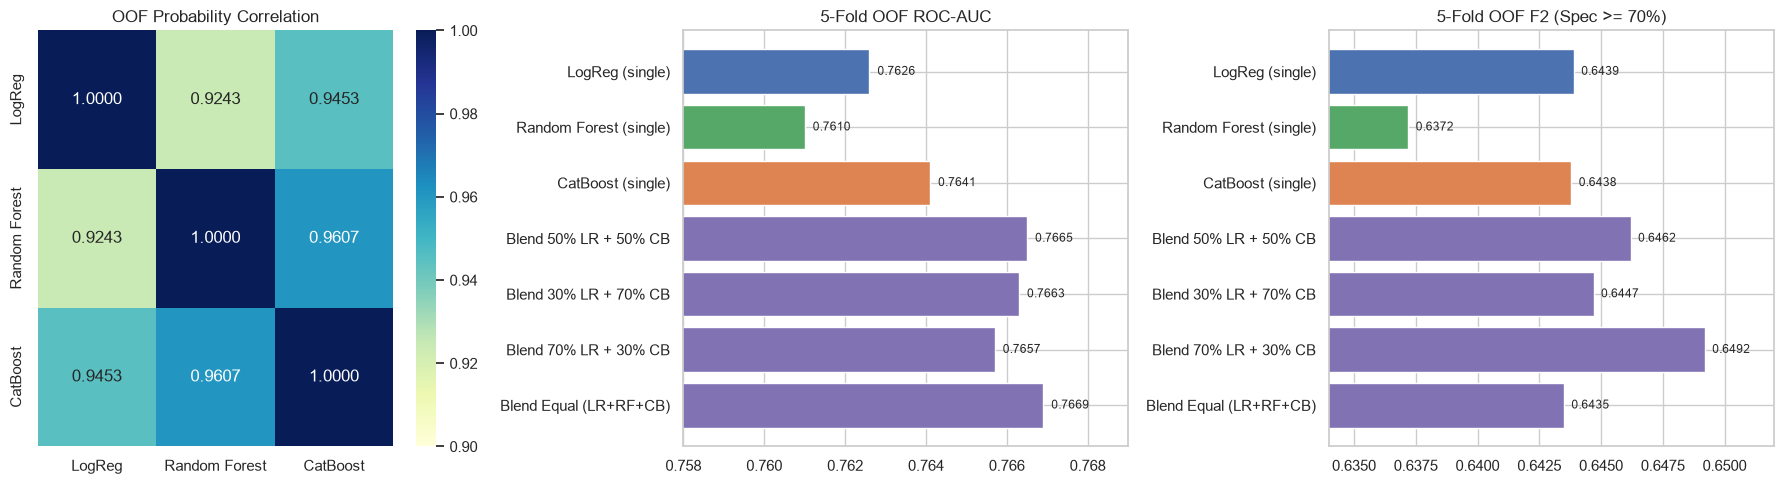

In [6]:
# plot prediction correlation heatmap and single vs blend ROC-AUC / F2 comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5.0))

sns.heatmap(corr_df, annot=True, fmt=".4f", cmap="YlGnBu", vmin=0.90, vmax=1.00, ax=axes[0])
axes[0].set_title("OOF Probability Correlation")

colors = ["#4c72b0", "#55a868", "#dd8452", "#8172b3", "#8172b3", "#8172b3", "#8172b3"]
y_pos = np.arange(len(blend_df))

b1 = axes[1].barh(y_pos, blend_df["roc_auc"], color=colors)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(blend_df["candidate"])
axes[1].invert_yaxis()
axes[1].set_xlim(0.758, 0.769)
axes[1].set_title("5-Fold OOF ROC-AUC")
for b in b1:
    val = b.get_width()
    axes[1].text(val + 0.0002, b.get_y() + b.get_height() / 2, f"{val:.4f}", va="center", fontsize=8.5)

b2 = axes[2].barh(y_pos, blend_df["f2"], color=colors)
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(blend_df["candidate"])
axes[2].invert_yaxis()
axes[2].set_xlim(0.634, 0.652)
axes[2].set_title("5-Fold OOF F2 (Spec >= 70%)")
for b in b2:
    val = b.get_width()
    axes[2].text(val + 0.0003, b.get_y() + b.get_height() / 2, f"{val:.4f}", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()


Combining linear LogReg and tree-based CatBoost gives a small but consistent gain because the two models catch slightly different cases. We lock the simple 50/50 blend (threshold 0.319) to keep the final setup clean and avoid tuning extra blend weights.


## 4. Lock Final Model Selection

We save the locked model configuration (50% LogReg + 50% CatBoost on practical_20, threshold 0.319) and its 5-fold CV summary into experiments/final_selection.json for the single-shot final test in Stage 10.


In [7]:
# compute fixed referral table for the locked 50/50 blend and save final_selection.json
best_blend_name = "Blend 50% LR + 50% CB"
best_blend_oof = blend_oofs[best_blend_name]
best_blend_row = blend_df.loc[blend_df["candidate"] == best_blend_name].iloc[0].to_dict()

order = np.argsort(-best_blend_oof, kind="mergesort")
blend_ref_rows = []
for rate in [0.20, 0.30, 0.40]:
    k = int(round(rate * len(y)))
    thr_r = float(best_blend_oof[order[k - 1]])
    m_r = evaluate.compute_metrics(y, best_blend_oof, thr_r)
    referred = int(m_r["tp"] + m_r["fp"])
    blend_ref_rows.append({
        "referral_rate": rate,
        "referred_count": referred,
        "actual_referral_rate": round(referred / len(y), 4),
        "threshold": m_r["threshold"],
        "recall": m_r["recall"],
        "specificity": m_r["specificity"],
        "precision": m_r["precision"],
        "f2": m_r["f2"],
        "tp": m_r["tp"],
        "fp": m_r["fp"],
        "tn": m_r["tn"],
        "fn": m_r["fn"],
    })

display(pd.DataFrame(blend_ref_rows))

cb_params = dict(cv_data["catboost"]["best_params"])
cb_params.setdefault("random_seed", evaluate.SEED)

final_selection = {
    "selected_model": "blend_50_logreg_50_catboost",
    "feature_set": "practical_20",
    "features": cv_data["catboost"]["features"],
    "components": {
        "logreg": {
            "weight": 0.5,
            "params": cv_data["logreg"]["best_params"],
        },
        "catboost": {
            "weight": 0.5,
            "params": cb_params,
        },
    },
    "locked_threshold": float(best_blend_row["threshold"]),
    "cv_metrics": {k: v for k, v in best_blend_row.items() if k != "candidate"},
    "referral_table": blend_ref_rows,
    "single_model_summary": comp_df.to_dict(orient="records"),
    "blend_comparison": blend_df.to_dict(orient="records"),
}

sel_path = exp_dir / "final_selection.json"
sel_path.write_text(json.dumps(final_selection, indent=2) + "\n", encoding="utf-8")
print("Saved:", sel_path)
print("Locked model:", final_selection["selected_model"], "| feature_set:", final_selection["feature_set"], "| threshold:", final_selection["locked_threshold"])


,referral_rate,referred_count,actual_referral_rate,threshold,recall,specificity,precision,f2,tp,fp,tn,fn
0,0.2,2476,0.2,0.4817,0.3910,0.8803,0.5788,0.4181,1433,1043,7670,2232
1,0.3,3713,0.3,0.4043,0.5482,0.8044,0.5411,0.5467,2009,1704,7009,1656
2,0.4,4951,0.4,0.3324,0.6791,0.7174,0.5027,0.6346,2489,2462,6251,1176


Saved: ../experiments/final_selection.json
Locked model: blend_50_logreg_50_catboost | feature_set: practical_20 | threshold: 0.319


## Bonus: Cycle and Age Subset Check

In 05d_subset_models.ipynb, we tested year- and age-restricted questions (oral health in 2011-2014, sleep and symptoms in 2015-2018, and age 36+) inside their own valid cohorts. Those extra questions gave only small F2 shifts without improving ROC-AUC, supporting practical_20 as our main all-year feature set.
